# Traffic Task 2 | What Is Available at Forecast Time?

**Keep observations at T; block information after T from features, fitting, and model selection.**

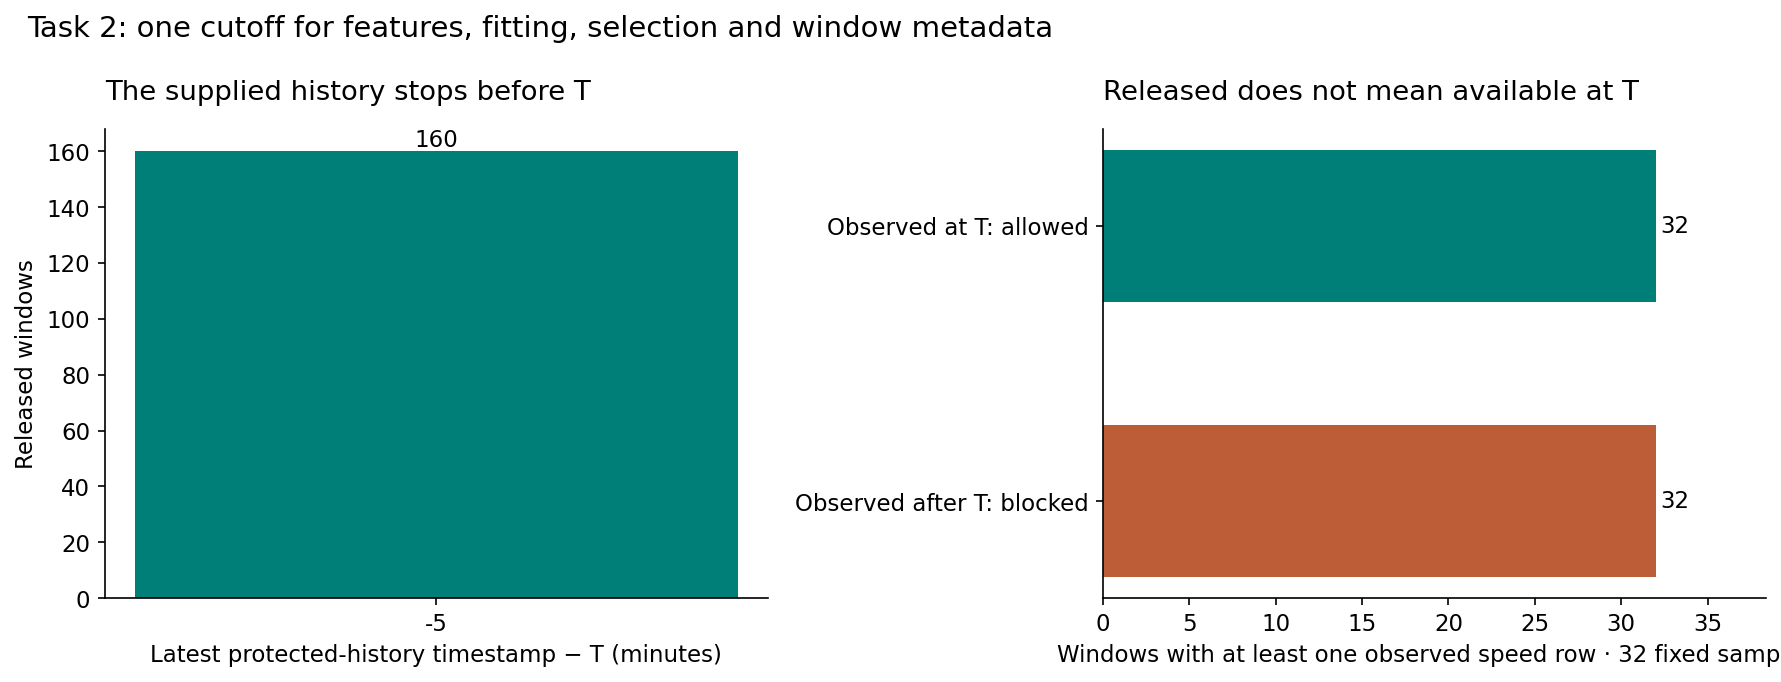

**160/160 protected histories across 8 panels**
match T−60 through T−5. Among **32 fixed calendar samples**,
**32** contain observed speed at T and
**32** contain later observations that an earlier forecast must not use.

**Recorded audit cost: 14.51 seconds, CPU only; no GPU, model fitting, Internet, or submission.**
The chart records the private audit, not a forecast score. Run All recomputes the tables and checks source identities below.
Download `causal_cutoff.py` from Output to audit your own declared lineage.


## 1. The current contract

Let **T** be the forecast origin, in the release's UTC clock. The host's current answers distinguish
the **allowed information boundary** from the **supplied historical input**:

| Input | May a forecast at T use it? |
|---|---|
| Released observation timestamped exactly T | Yes |
| Supplied `window_history`: T−60, T−55, …, T−5 | Yes; 12 five-minute steps |
| Released row after T, even after the blanked buffer | No |
| Fitting or threshold selection using data after T | No |
| Released origins in `window_index` at or before T | Yes, including the documented selection rule |
| A future origin in `window_index` | No |

Primary sources, checked **15 October 2026**:
[origin and endpoints](https://www.kaggle.com/competitions/2026-ieee-big-data-traffic-flow-bench/discussion/745700),
[fitting and split history](https://www.kaggle.com/competitions/2026-ieee-big-data-traffic-flow-bench/discussion/748789),
[protected histories](https://www.kaggle.com/competitions/2026-ieee-big-data-traffic-flow-bench/discussion/749278),
and the [current Rules](https://www.kaggle.com/competitions/2026-ieee-big-data-traffic-flow-bench/rules).
The current official persistence source already explains that it conservatively uses T−5.
This notebook does not claim that source is still broken.


## 2. Copy the checker into your own pipeline

Each row declares the latest raw source timestamp for one dependency of one forecast. For an aggregate
feature, include **all** inputs that influenced it, not just the timestamp of the resulting feature row.
For a fitted model, record the latest information used during fitting, including preprocessing and target availability.
For a selected model or threshold, record its selection data too. The forecast origin is a cutoff, not a data timestamp.

**ALLOWED** means the declared timestamps satisfy the required stages. **BLOCKED** means a declared source
is later than T. **UNKNOWN** means lineage is missing or invalid. Both BLOCKED and UNKNOWN should stop a forecast.
Explicit timeless metadata is supported; a static flag cannot exempt a non-null future timestamp.


In [ ]:
"""Original Task 2 declared-lineage checker. Apache-2.0.

No fitting or forecast is performed. Use only on lawfully released inputs.
Naive timestamps are interpreted on the same UTC comparison clock; callers
must first normalize their own competition calendar consistently.
"""
from __future__ import annotations

import pandas as pd

STAGES = ("feature", "fit", "selection", "window_metadata")
REQUIRED_COLUMNS = ("window_id", "origin_T", "item", "stage", "max_source_time")


def causal_slice(frame, origin_T, time_column="timestamp"):
    """Select <=T, including T. Reject unknown timestamps before selecting."""
    origin = pd.to_datetime(origin_T, utc=True, errors="coerce")
    stamps = pd.to_datetime(frame[time_column], utc=True, errors="coerce")
    if pd.isna(origin) or stamps.isna().any():
        raise ValueError("Unknown origin or source timestamp; cannot safely slice.")
    return frame.loc[stamps <= origin].copy()


def audit_dependencies(manifest, required_stages=("feature", "fit", "selection")):
    """Audit every declared dependency and aggregate conservatively per window.

    manifest columns: window_id, origin_T, item, stage, max_source_time;
    optional static_source bool for genuinely timeless, released metadata.
    A caller using a rule with no learned fit or selection may explicitly pass
    required_stages=('feature',), documenting that narrower scope.

    ALLOWED means only that all required DECLARED stages have timestamps <=T.
    It is not a certification of undeclared features or training code.
    """
    missing = set(REQUIRED_COLUMNS) - set(manifest.columns)
    if missing:
        raise ValueError(f"Missing manifest columns: {sorted(missing)}")
    if manifest.empty:
        raise ValueError("Empty lineage cannot prove an allowed forecast.")
    if set(required_stages) - set(STAGES) or not required_stages:
        raise ValueError("Explicit required stages must be nonempty and recognized.")
    result = manifest.copy().reset_index(drop=True)
    if result[["window_id", "item", "stage"]].isna().any().any():
        raise ValueError("Window, item and stage identities must be present.")
    if not result.stage.isin(STAGES).all():
        raise ValueError("Unrecognized dependency stage.")
    origins = pd.to_datetime(result.origin_T, utc=True, errors="coerce")
    stamps = pd.to_datetime(result.max_source_time, utc=True, errors="coerce")
    static = result.get("static_source", pd.Series(False, index=result.index))
    if not static.map(lambda value: isinstance(value, bool)).all():
        raise ValueError("static_source must contain explicit booleans, not strings.")
    # Null timestamp + explicit static means timeless; a malformed non-null
    # timestamp remains unknown, even if somebody sets the static flag.
    timeless = static & result.max_source_time.isna()
    known = origins.notna() & (stamps.notna() | timeless)
    future = origins.notna() & stamps.notna() & (stamps > origins)
    result["verdict"] = "UNKNOWN"
    result["reason"] = "Missing or invalid timestamp lineage"
    result.loc[known & ~future, ["verdict", "reason"]] = ["ALLOWED", "Declared sources are at or before T"]
    result.loc[known & timeless, "reason"] = "Explicit timeless released metadata"
    result.loc[future, ["verdict", "reason"]] = ["BLOCKED", "Declared source is later than this forecast origin"]
    result["minutes_after_T"] = (stamps-origins).dt.total_seconds()/60
    records = []
    for window, group in result.groupby("window_id", sort=False):
        parsed = origins.loc[group.index]
        inconsistent_origin = parsed.isna().any() or parsed.nunique() != 1
        missing_stages = sorted(set(required_stages)-set(group.stage))
        verdict = ("BLOCKED" if (group.verdict=="BLOCKED").any() else
                   "UNKNOWN" if inconsistent_origin or missing_stages or (group.verdict=="UNKNOWN").any() else
                   "ALLOWED")
        records.append({"window_id": window, "verdict": verdict,
                        "declared_items": len(group), "blocked_items": int((group.verdict=="BLOCKED").sum()),
                        "unknown_items": int((group.verdict=="UNKNOWN").sum()),
                        "missing_stages": ",".join(missing_stages), "consistent_origin": not inconsistent_origin,
                        "scope": "DECLARED_DEPENDENCIES_ONLY"})
    return result, pd.DataFrame(records)


def boundary_examples():
    """Authored documentation cases; not observed mistakes by competitors."""
    origin = pd.Timestamp("2031-03-01T12:00:00Z")
    rows = []
    for case in ("at_T", "future_feature", "future_fit", "future_selection", "unknown_lineage"):
        for stage in ("feature", "fit", "selection"):
            stamp = origin if stage=="feature" else origin-pd.Timedelta(days=1)
            if case==f"future_{stage}":
                stamp = origin+pd.Timedelta(minutes=5)
            if case=="unknown_lineage" and stage=="fit":
                stamp = pd.NaT
            rows.append({"window_id":case,"origin_T":origin,"item":f"authored_{stage}",
                         "stage":stage,"max_source_time":stamp})
    detail, windows = audit_dependencies(pd.DataFrame(rows))
    expected={"at_T":"ALLOWED", "future_feature":"BLOCKED", "future_fit":"BLOCKED",
              "future_selection":"BLOCKED", "unknown_lineage":"UNKNOWN"}
    assert windows.set_index("window_id").verdict.to_dict()==expected
    return detail, windows


### Boundary examples, authored for documentation

These cases demonstrate the rule; they are not observed mistakes by other participants.
The equality case passes. Future features, future fitting, future selection, and unknown fitting lineage fail closed.


In [ ]:
from IPython.display import display, Markdown, FileLink
example_detail, example_windows = boundary_examples()
display(example_windows[['window_id', 'verdict', 'missing_stages']])

# A convenience slice rejects unknown timestamps before filtering.
probe = pd.DataFrame({'timestamp': ['2031-03-01T11:55:00Z', '2031-03-01T12:00:00Z', '2031-03-01T12:05:00Z']})
assert len(causal_slice(probe, '2031-03-01T12:00:00Z')) == 2
unknown = probe.copy()
unknown.loc[0, 'timestamp'] = None
try:
    causal_slice(unknown, '2031-03-01T12:00:00Z')
except ValueError:
    print('Unknown timestamp rejected before slicing.')
else:
    raise AssertionError('Unknown timestamps must not silently disappear.')


## 3. Audit the actual released windows

Attach the official competition input. There is no external dataset, model weight, Internet download, or GPU.
The audit reads every March/April `window_index` and protected history, checks identities, and compares each
complete timestamp set with the documented twelve steps. The actual origin field is `forecast_origin`, verified
in the official Data Explorer. It does not infer T from an observed speed or a guessed calendar boundary.

For the ordinary masked calendar, choose the **earliest two origins per panel and month**, before looking
at values. Count released non-null speed rows before, at, and after T. Reading future rows in this diagnostic
is solely an availability audit; they are never passed into a forecast. No queue labels are read or reconstructed.

Before execution, the usefulness condition is fixed: ≥20 windows across ≥3 panels; all histories match;
all declared reference histories pass; ≥12 calendar samples; actual released observations exist both at T
and after T in at least one sample. Failure is reported without changing the sample or cutoff.


In [ ]:
"""Original released-input audit. Apache-2.0. Runs on Kaggle CPU only.

This inspects availability and declared lineage, never hidden labels or forecasts.
"""
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def find_release(input_root=Path('/kaggle/input')):
    roots = sorted({path.parent.parent for path in input_root.rglob('competition_contract.json')
                    if path.parent.name == 'config' and (path.parent.parent / 'task2').is_dir()})
    if len(roots) != 1:
        raise ValueError(f'Attach exactly one current official Traffic release; found {len(roots)}.')
    return roots[0]


def run_released_audit(origin_column, audit_dependencies, boundary_examples):
    started = time.monotonic()
    root = find_release()
    source_files = []
    window_tables = []
    lineage_rows = []
    index_tables = []
    # Both released evaluation months; train is not used to invent queue labels.
    for path in sorted((root / 'task2').glob('*/*/window_index.csv')):
        split, panel = path.parent.name, path.parent.parent.name
        if split not in ('validation', 'private'):
            continue
        index = pd.read_csv(path, dtype={'window_id': str})
        required = {'window_id', origin_column, 'panel', 'split'}
        if required - set(index.columns):
            raise ValueError(f'Unexpected official index schema: {list(index.columns)}')
        if index.empty:
            continue
        if index.window_id.duplicated().any() or not index.panel.eq(panel).all() or not index.split.eq(split).all():
            raise ValueError('Window IDs or panel/split identities do not match the official directory.')
        index['origin_T'] = pd.to_datetime(index[origin_column], utc=True, errors='raise')
        if index.origin_T.isna().any():
            raise ValueError('Unknown official origins.')
        index_tables.append(index[['window_id', 'origin_T', 'panel', 'split']])
        history_path = path.with_name('window_history.parquet')
        schema = pq.read_schema(history_path)
        expected = {'window_id', 'timestamp', 'link_id', 'speed_kmh', 'is_score_eligible'}
        if expected - set(schema.names):
            raise ValueError(f'Unexpected official history schema: {schema.names}')
        history = pd.read_parquet(history_path, columns=['window_id', 'timestamp'])
        history['window_id'] = history.window_id.astype(str)
        history['timestamp'] = pd.to_datetime(history.timestamp, utc=True, errors='raise')
        if history.timestamp.isna().any() or set(history.window_id) != set(index.window_id):
            raise ValueError('History has unknown timestamps or missing/extra window IDs.')
        joined = history.merge(index[['window_id', 'origin_T']], on='window_id', how='left', validate='many_to_one')
        joined['offset_minutes'] = (joined.timestamp - joined.origin_T).dt.total_seconds() / 60
        grouped = joined.groupby('window_id', sort=True)
        audit = grouped.agg(history_rows=('timestamp', 'size'), history_stamps=('timestamp', 'nunique'),
                            first_offset=('offset_minutes', 'min'), last_offset=('offset_minutes', 'max'))
        # Compare the complete timestamp set, not just min/max endpoints.
        canonical = tuple(range(-60, 0, 5))
        offsets = grouped.offset_minutes.apply(lambda s: tuple(sorted(s.unique())))
        audit['documented_12_steps'] = offsets.map(lambda values: values == canonical)
        audit = index[['window_id', 'origin_T', 'panel', 'split']].merge(audit.reset_index(), on='window_id', validate='one_to_one')
        window_tables.append(audit)
        maximum = grouped.timestamp.max()
        ordered_origins = index.origin_T.sort_values()
        for row in index.itertuples(index=False):
            # This example has no learned model or threshold selection. Both
            # required stages are declared; metadata is truncated per origin.
            lineage_rows.extend([
                {'window_id': row.window_id, 'origin_T': row.origin_T,
                 'item': 'protected_window_history', 'stage': 'feature',
                 'max_source_time': maximum.loc[row.window_id]},
                {'window_id': row.window_id, 'origin_T': row.origin_T,
                 'item': 'released_origins_up_to_T', 'stage': 'window_metadata',
                 'max_source_time': ordered_origins.loc[ordered_origins <= row.origin_T].max()},
            ])
        for source in (path, history_path):
            source_files.append({'path': source.relative_to(root).as_posix(), 'bytes': source.stat().st_size,
                                 'sha256': sha256_file(source)})
    if not window_tables:
        raise ValueError('No released evaluation windows found; input-contract audit cannot run.')
    windows = pd.concat(window_tables, ignore_index=True)
    if windows.window_id.duplicated().any():
        raise ValueError('Window IDs must be globally unique across inspected panels/splits.')
    manifests = pd.DataFrame(lineage_rows)
    detail, verdicts = audit_dependencies(manifests, required_stages=('feature', 'window_metadata'))
    windows = windows.merge(verdicts, on='window_id', validate='one_to_one')
    # A bounded calendar audit: earliest two origins per panel/month, selected
    # without looking at observed values. Read released timestamps and presence
    # for auditing only. These rows are never fed into a forecast.
    selected = windows.sort_values(['panel', 'split', 'origin_T', 'window_id']).groupby(['panel', 'split'], sort=True).head(2)
    samples = []
    for row in selected.itertuples(index=False):
        day = row.origin_T.strftime('%Y-%m-%d')
        folder = root / 'corridors' / row.panel / row.split / 'mainline_states_masked'
        # The official calendar filenames use YYYY_MM_DD, while origins are
        # UTC ISO dates. Accept only these two exact date representations.
        day_tokens = (day, day.replace('-', '_'))
        parts = sorted(p for p in folder.rglob('*.parquet')
                       if any(token in str(p.relative_to(folder)) for token in day_tokens))
        if not parts:
            raise ValueError(f'No current masked mainline file for {row.panel}/{row.split}/{day}.')
        available = pd.concat([pd.read_parquet(p, columns=['timestamp', 'speed_kmh']) for p in parts], ignore_index=True)
        stamps = pd.to_datetime(available.timestamp, utc=True, errors='raise')
        if stamps.isna().any():
            raise ValueError('Unknown calendar timestamps.')
        seen = available.speed_kmh.notna()
        samples.append({'window_id': row.window_id, 'panel': row.panel, 'split': row.split,
                        'origin_T': row.origin_T, 'calendar_rows_at_T': int(stamps.eq(row.origin_T).sum()),
                        'observed_speed_rows_at_T': int((stamps.eq(row.origin_T) & seen).sum()),
                        'observed_speed_rows_before_T': int((stamps.lt(row.origin_T) & seen).sum()),
                        'observed_speed_rows_after_T': int((stamps.gt(row.origin_T) & seen).sum()),
                        'max_released_timestamp': stamps.max(), 'source_files': len(parts)})
        for source in parts:
            relative = source.relative_to(root).as_posix()
            if not any(record['path'] == relative for record in source_files):
                source_files.append({'path': relative, 'bytes': source.stat().st_size,
                                     'sha256': sha256_file(source)})
        if time.monotonic() - started > 1200:
            raise TimeoutError('Bounded audit exceeded its 20-minute internal budget.')
    samples = pd.DataFrame(samples)
    example_detail, examples = boundary_examples()
    publish_gate = bool(windows.documented_12_steps.all() and windows.verdict.eq('ALLOWED').all()
                        and windows.panel.nunique() >= 3 and len(windows) >= 20
                        and len(samples) >= 12 and samples.observed_speed_rows_at_T.gt(0).any()
                        and samples.observed_speed_rows_after_T.gt(0).any())
    contract_path = root / 'config' / 'competition_contract.json'
    summary = {'status': 'RELEASED_INPUT_AUDIT_ONLY', 'publish_gate': publish_gate,
               'windows': len(windows), 'panels': windows.panel.nunique(),
               'splits': sorted(windows.split.unique().tolist()),
               'history_rows': int(windows.history_rows.sum()),
               'history_steps_match': int(windows.documented_12_steps.sum()),
               'declared_windows_allowed': int(windows.verdict.eq('ALLOWED').sum()),
               'sampled_calendar_windows': len(samples),
               'samples_with_observations_at_T': int(samples.observed_speed_rows_at_T.gt(0).sum()),
               'samples_with_released_future': int(samples.observed_speed_rows_after_T.gt(0).sum()),
               'origin_column': origin_column, 'runtime_seconds': time.monotonic() - started,
               'learned_fit_performed': False, 'forecast_performed': False,
               'formal_submission': False, 'queue_score': None,
               'source_files': source_files,
               'contract_sha256': sha256_file(contract_path)}
    return summary, windows, samples, detail, examples, example_detail


In [ ]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
from importlib.metadata import version

summary, windows, calendar, detail, example_windows, example_detail = run_released_audit(
    'forecast_origin', audit_dependencies, boundary_examples)
summary['environment'] = {name: version(name) for name in ('pandas', 'numpy', 'pyarrow', 'matplotlib')}
WORK = Path('/kaggle/working')
(WORK / 'summary.json').write_text(json.dumps(summary, indent=2))
display(windows.groupby(['split', 'panel']).agg(
    windows=('window_id', 'size'), history_rows=('history_rows', 'sum'),
    matched_steps=('documented_12_steps', 'sum'), earliest_offset=('first_offset', 'min'),
    latest_offset=('last_offset', 'max')))
display(Markdown(f"**{summary['windows']} windows / {summary['panels']} panels; "
                 f"{summary['history_steps_match']} histories match the twelve-step contract.** "
                 f"Measured audit runtime: **{summary['runtime_seconds']:.2f} s**, CPU only. "
                 f"Usefulness condition: **{summary['publish_gate']}**."))


In [ ]:
# The first-screen chart records the completed private audit. Stop if a later
# release changes any inspected input; do not silently pair old counts with new data.
expected_source_files = {'task2/D12_I5_N/private/window_index.csv': '4fdcd00843bbdff1af50235763168a2b3138fe6a0b7ba75ce80380b4a2886f13', 'task2/D12_I5_N/private/window_history.parquet': '54e19aa91ef74f92819b4e13882edde4b80f5f12f84124c05ab3a13fe03e4481', 'task2/D12_I5_N/validation/window_index.csv': '722d7351f8ffac6920fc602d6d6a19cabbdad72817252936ad68b25b37a00e6e', 'task2/D12_I5_N/validation/window_history.parquet': 'c09b68b3e2990623e24e389c6a43950cda231ea7932ef9313ef4172de8808f30', 'task2/D12_I5_S/private/window_index.csv': 'ee94b3b9f51a8b2a1a4358711459de2393bb0027013b2ad37dd639adfeae6ca4', 'task2/D12_I5_S/private/window_history.parquet': 'b88d7fb5da5b0ee7fb244f219814a3ecad20f46a6f73cc917b3e496c9f1dc8bf', 'task2/D12_I5_S/validation/window_index.csv': '1cd1b0fdfa6ce5856a350e59cf26d93f9ac8c88294f2bd3ea3795b784826be9e', 'task2/D12_I5_S/validation/window_history.parquet': 'e4de0544667c9b465f1b99e6e849acd34135fd955b18aa63f33aff932405a712', 'task2/D7_I10_E/private/window_index.csv': 'f538b1302798d2e027ad3a78d4212395fe503092c0fcfc75c027e43aeb0cce0d', 'task2/D7_I10_E/private/window_history.parquet': '6e16830d2424d8c5d502873d98ae6798df4d7cbe0c654c15958dfc4f987a79bb', 'task2/D7_I10_E/validation/window_index.csv': '9108125cb849927e12697ce2a2737f5fa4bad27e3beca02d7590929bef8c66b5', 'task2/D7_I10_E/validation/window_history.parquet': '67211dd7e492b865e12073428b1a79c24610c8b54fd931c0156f145acab1851c', 'task2/D7_I10_W/private/window_index.csv': 'ba1c5ec2c0881a8d668eb425bc7152b143cb2f13290c31848fd443f9351f3cad', 'task2/D7_I10_W/private/window_history.parquet': 'c2aaf72934d2ddea82d3ced788e022bf38932251726a6568d99f3cdf3197ee1a', 'task2/D7_I10_W/validation/window_index.csv': '11fc7f8d8b8216012fa89579d326c23f823385f8a672e06b9da91470f7429747', 'task2/D7_I10_W/validation/window_history.parquet': '05affef410c3e1c999c304a121279cb44cfe6c609b1368671b77f84669c476d1', 'task2/D7_I210_E/private/window_index.csv': '898d295a39813b374bad7ae5d344230f3959768f0ed2d73c7a9c1ac2941e2bfa', 'task2/D7_I210_E/private/window_history.parquet': 'd847eb3f4d24e3af26ebdda91df1c3d2864180a95f850316cd5e482947a0bb49', 'task2/D7_I210_E/validation/window_index.csv': '506ffcb3cb52a7b25f7ac870c4f1ba3a7489a5bf789de707272d1fb7de33d99b', 'task2/D7_I210_E/validation/window_history.parquet': 'f87eeb3e558f9ca82f29bf3097282a3f7ef40e84ce7f8e565743806d8dc15f00', 'task2/D7_I210_W/private/window_index.csv': 'd03b6ad93b652f38c517c1822127322671931230589960d3b3f702792edf3d10', 'task2/D7_I210_W/private/window_history.parquet': '0e22a87fc6f6d5272a2cc64a844a5c31d508633a6fd1f2fc04fbcfaf57a385f9', 'task2/D7_I210_W/validation/window_index.csv': '131efeaf9b5b6acb8e9cf554245122e14eaf49142880c26765ceadb3df39b8d5', 'task2/D7_I210_W/validation/window_history.parquet': '3e8162e0fe429abf3b1faa2a0bd4f7cfccbe5e813824af767b538b6e8f6fb26d', 'task2/D7_I405_N/private/window_index.csv': 'cfc51a42975f1e724a38018d6598b95ef84ffbd2afca0503efe374a40fa3f75a', 'task2/D7_I405_N/private/window_history.parquet': 'df451b23e8aeab9fb98485025164935b0c5a5fd6824042fa563b179d9482e010', 'task2/D7_I405_N/validation/window_index.csv': 'cf15de5175fd7f2efa9fa96a983250c623d4366a7c1a9d62d080e25c0ee35d3f', 'task2/D7_I405_N/validation/window_history.parquet': 'fe4619a084edae76b734ccd17f7e0a5a1c7b7f4c0aa48064130df6a62575cc51', 'task2/D7_I405_S/private/window_index.csv': '694ceed137dc3d8fc61006700582bcaf7e4f8b02da77c1b68ce1d03274665a2b', 'task2/D7_I405_S/private/window_history.parquet': '02f78991c7a0fdedc53be86160e115c08beec5882c417ef204207bf6b6e3bd96', 'task2/D7_I405_S/validation/window_index.csv': '738e754d282dcd2295cfb5d4138479332ed16de9c6b0602b66a8f53044c2dd71', 'task2/D7_I405_S/validation/window_history.parquet': '98eb49d36acbf1fbdff0ebc80e1adbbebf4e698a1ca73ce27c998400666c9ae4', 'corridors/D12_I5_N/private/mainline_states_masked/mask_regime=R3/synthetic_mainline_2031_04_01.parquet': 'f36811b5e65baf400454cf337bac7414f5498d2e5fb6619b8ba3368276e94b99', 'corridors/D12_I5_N/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_02.parquet': '50e2654d852d367f6912984cf8a3196cef0cdb97420a36efd72abf9b1d8461b0', 'corridors/D12_I5_N/validation/mainline_states_masked/mask_regime=R1/synthetic_mainline_2031_03_01.parquet': '2d1e565932e4eb30211c7848d855ed232cd67cd05c9b246b58cc533ae8d32576', 'corridors/D12_I5_S/private/mainline_states_masked/mask_regime=R1/synthetic_mainline_2031_04_01.parquet': '2fcb40e25708c620a4b8bc6cc4c16511ab50b415fa11f7272dff7a3b76be573f', 'corridors/D12_I5_S/private/mainline_states_masked/mask_regime=R1/synthetic_mainline_2031_04_02.parquet': '725da23089e9fce57685c14e8d90cf0acd65b783418091b23e697229d862c0b0', 'corridors/D12_I5_S/validation/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_03_01.parquet': '22647fd9de310980d16189c1dd4f907643f8896d732ba8c732ff9356e7334ab7', 'corridors/D7_I10_E/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_01.parquet': 'b87e6bb6a1e05d153b6e1dc366d22a56004a29e36ff170e349119367867e50c2', 'corridors/D7_I10_E/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_02.parquet': '9482271fdb82be22f9e5fa1efbdd2955a5b60435c491e5cc994217c49ee1ac7f', 'corridors/D7_I10_E/validation/mainline_states_masked/mask_regime=R3/synthetic_mainline_2031_03_01.parquet': 'ba782ef5e80ae97ba547a25b2e527229979db9134f01b84aadd0dc68b27bc7b6', 'corridors/D7_I10_W/private/mainline_states_masked/mask_regime=R1/synthetic_mainline_2031_04_03.parquet': '42b7c47f946508ad6ac3bdb6aaac04d07d087b563e440d047a05197a50eb46dc', 'corridors/D7_I10_W/private/mainline_states_masked/mask_regime=R1/synthetic_mainline_2031_04_05.parquet': 'e902bf557025fb14878d12d8e128a874fd0561b6e6ec5a9776a6936d94b03049', 'corridors/D7_I10_W/validation/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_03_01.parquet': 'bcf4470844f65f75e990d9787182890df185c5f68a5e6820b7b468e97aa9c3ef', 'corridors/D7_I10_W/validation/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_03_02.parquet': '8c0b34319d5caf5b04fe6642287fe4ca0add9116646a4e078222f78f027f096c', 'corridors/D7_I210_E/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_01.parquet': '065b7056125f66c4d9c415496417131eaa488050b3f5429547a0091539af4d0a', 'corridors/D7_I210_E/validation/mainline_states_masked/mask_regime=R3/synthetic_mainline_2031_03_01.parquet': '48a09bfe35bcfd488b653af7574dbe5c395093610879a1c918c6117557ecc5b7', 'corridors/D7_I210_W/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_01.parquet': '2b15dbb4b71a7eccbccb16e6694dd78a4c124f09641e05cfdc171826ef26d4f8', 'corridors/D7_I210_W/validation/mainline_states_masked/mask_regime=R3/synthetic_mainline_2031_03_01.parquet': '1b076d130581ce406cce6abc2492201e3abfe4d5ff89c563453386ad136c6969', 'corridors/D7_I405_N/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_01.parquet': 'a574d20e133b1ed1ff396ac4308ba8365326d0a8c1bcce610747b858931ebe92', 'corridors/D7_I405_N/validation/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_03_01.parquet': '8d741ff4420befa8839a41f16357eed81815623a7e5e9747c5fdeb98ced65a4e', 'corridors/D7_I405_S/private/mainline_states_masked/mask_regime=R3/synthetic_mainline_2031_04_02.parquet': 'a2f197845bb4ba661c93a05edbb94a11a4d6e65e46f13b97fe3d703028c77c48', 'corridors/D7_I405_S/private/mainline_states_masked/mask_regime=R2/synthetic_mainline_2031_04_03.parquet': '7a6d3f4b2f965b9b1fb4dc74211819a5ec0c2e6b8d0201ba16b5c48b07068b0a', 'corridors/D7_I405_S/validation/mainline_states_masked/mask_regime=R1/synthetic_mainline_2031_03_01.parquet': '4d13b84e38f7a4e57ab4dcb88f1196979099c3f8b4b89f00b0d53eb5d8990ced'}
observed_source_files = {item['path']: item['sha256'] for item in summary['source_files']}
assert observed_source_files == expected_source_files, 'Official inspected inputs changed; refresh the recorded audit.'
assert summary['contract_sha256'] == 'b2e40965cfd426d503dc579825dcfc37541fafc34594ff5d98f99e53ba5c4d0c'


## 4. A released file can contain both usable and unusable rows

The left chart reports actual history endpoints. The right chart shows the ordinary calendar audit across
the fixed samples. An observation can exist in a released file and still be unavailable to an earlier forecast.
These counts are an input-availability result, not a model score or an estimate of leaderboard improvement.


In [ ]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
left = windows.groupby('last_offset').size()
axes[0].bar([str(int(x)) for x in left.index], left.values, color='#007f78', width=.6)
axes[0].set_xlabel('Latest protected-history timestamp − T (minutes)')
axes[0].set_ylabel('Released windows')
axes[0].set_title('The supplied history stops before T', loc='left', pad=14)
for i, value in enumerate(left.values):
    axes[0].text(i, value, str(value), ha='center', va='bottom')
at_count = int(calendar.observed_speed_rows_at_T.gt(0).sum())
future_count = int(calendar.observed_speed_rows_after_T.gt(0).sum())
bars = axes[1].barh(['Observed at T: allowed', 'Observed after T: blocked'],
                    [at_count, future_count], color=['#007f78', '#bd5d38'], height=.55)
axes[1].set_xlim(0, len(calendar) * 1.2)
axes[1].invert_yaxis()
axes[1].set_xlabel(f'Windows with at least one observed speed row\n{len(calendar)} fixed samples')
axes[1].set_title('Released does not mean available at T', loc='left', pad=14)
for bar, value in zip(bars, [at_count, future_count]):
    axes[1].text(value + .25, bar.get_y()+bar.get_height()/2, str(value), va='center')
fig.suptitle('Task 2: one cutoff for features, fitting, selection and window metadata', x=.02, ha='left', fontsize=14)
fig.tight_layout()
fig.savefig(WORK / 'causal_cutoff_audit.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
display(calendar.groupby(['split', 'panel']).agg(
    sampled_windows=('window_id', 'size'), observed_at_T=('observed_speed_rows_at_T', 'sum'),
    released_future_rows=('observed_speed_rows_after_T', 'sum')))


## 5. Use it before emitting predictions

The audited reference here has no learned fit or threshold selection, so its required stages are explicitly
`('feature', 'window_metadata')`. A learned pipeline should retain the default feature/fit/selection requirements,
and add window metadata if it uses it. Merely attaching a plausible timestamp does not prove correct lineage.


In [ ]:
# Example integration for your own fully declared manifest:
# rows, forecasts = audit_dependencies(my_manifest)
# assert set(forecasts.window_id) == set(official_index.window_id)
# if not forecasts.verdict.eq('ALLOWED').all():
#     raise RuntimeError('Do not emit predictions: unresolved or future lineage.')

# This reference manifest covers every official window inspected above.
assert set(detail.window_id) == set(windows.window_id)
print('No fitting, threshold optimization, forecasting, or competition submission was performed.')


## 6. Download the helper and audit tables

Output contains the original checker, per-window availability summaries, fixed sample audit, and the authored
boundary examples. `summary.json` records package versions, source file identities and measured runtime.
It contains no raw speed values, model weights, hidden labels, or competition submission file.


In [ ]:
import inspect
checker_export = '"""Original Task 2 declared-lineage helper. Apache-2.0."""\nimport pandas as pd\n'
checker_export += 'STAGES = ' + repr(STAGES) + '\n'
checker_export += 'REQUIRED_COLUMNS = ' + repr(REQUIRED_COLUMNS) + '\n\n'
checker_export += '\n\n'.join(inspect.getsource(function) for function in
                                (causal_slice, audit_dependencies, boundary_examples))
(WORK / 'causal_cutoff.py').write_text(checker_export)
windows.to_csv(WORK / 'window_history_audit.csv', index=False)
calendar.to_csv(WORK / 'calendar_availability_audit.csv', index=False)
detail.to_csv(WORK / 'reference_declared_lineage.csv', index=False)
example_detail.to_csv(WORK / 'authored_boundary_examples.csv', index=False)
for name in ('causal_cutoff.py', 'window_history_audit.csv', 'calendar_availability_audit.csv',
             'reference_declared_lineage.csv', 'authored_boundary_examples.csv', 'summary.json', 'causal_cutoff_audit.png'):
    display(FileLink(str(WORK / name)))


## Limitations and credit

- This checks **declared dependency timestamps**. It cannot discover undeclared leakage, prove a feature's
  true information availability, or certify an arbitrary pipeline. An observed timestamp can precede its actual
  publication time in another dataset; use the true availability time when adapting this elsewhere.
- Calendar presence is sampled at the earliest two origins per panel/month, not a census of every day.
  All March/April protected histories are inspected. Windows are not independent statistical replicates.
- No forecast is trained and no local queue IoU is reported. The current Data page withholds queue labels
  on every split. The checker makes no leaderboard, prize, or performance claim.
- Row presence at T does not guarantee a valid value for every station/channel. Missing ramp observations
  are missing evidence, not measured zero. Offline Tasks 1/3/4 have a different information contract.
- Rules may change. Recheck the linked host answers and current Evaluation before using this in a submission.

Original checker, audit, and figures: **Apache-2.0**. Official data remains subject to the competition rules.
Schema and baseline context: [official TrafficFlowBench repository](https://github.com/jacky850/trafficflowbench-public),
MIT, copyright 2026 TrafficFlowBench organizers. No third-party executable was downloaded or run.
The existing [directional reconstruction notebook](https://www.kaggle.com/code/yanamiiannaa/trafficflow-directional-features-safe-profiles)
covers a different, offline Task 1 method and warns against reusing its future observations for Task 2.
